# DS-01: Customer Lifetime Value and Churn Intelligence System

### Nexvia Technologies — Data Science Internship

---

## 1. Project Overview

This project focuses on developing a Customer Lifetime Value (CLV) and Churn Intelligence System to understand customer behaviour, predict customer churn, estimate customer lifetime value, and identify effective customer retention strategies.

The objective is to transform customer data into actionable business insights using machine learning, survival analysis, explainable AI, and uplift modelling.

### Project Objectives

1. Analyse customer behaviour and identify churn patterns.
2. Develop machine learning models to predict customer churn.
3. Apply explainable AI techniques to understand model predictions.
4. Perform customer survival analysis.
5. Estimate Customer Lifetime Value (CLV).
6. Apply uplift modelling to identify customers most likely to respond to retention campaigns.
7. Develop actionable customer retention strategies.

### Technology Stack

- **Programming:** Python
- **Data Analysis:** Pandas, NumPy
- **Machine Learning:** LightGBM
- **Explainable AI:** SHAP
- **Survival Analysis:** Lifelines
- **Uplift Modelling:** CausalML
- **Database:** PostgreSQL
- **Dashboard:** Streamlit

---

**Project:** DS-01  
**Domain:** Customer Intelligence  
**Organisation:** Nexvia Technologies

In [2]:
# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# System utilities
import os
import warnings

# Display settings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Base libraries imported successfully!")

Base libraries imported successfully!


## 2. Environment and Dependency Verification

Before beginning data analysis, we verify that the required Python libraries are installed and available.

This ensures a reproducible development environment and helps identify missing dependencies before implementation.

In [4]:
from pathlib import Path
import requests

# DS-01 project directory
PROJECT_ROOT = Path.cwd().parent

# Dataset directories
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Dataset source
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

# Download destination
DATA_PATH = RAW_DATA_DIR / "Telco-Customer-Churn.csv"

# Download dataset
response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

DATA_PATH.write_bytes(response.content)

print("Dataset downloaded successfully!")
print(f"Location: {DATA_PATH}")
print(f"Size: {DATA_PATH.stat().st_size / 1024:.2f} KB")

Dataset downloaded successfully!
Location: c:\Projects\Nexvia-Technologies-Data-Science-Internship\data\raw\Telco-Customer-Churn.csv
Size: 947.71 KB


In [5]:
# Load the dataset
df = pd.read_csv(DATA_PATH)

# Display first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
df.info()

Dataset Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043

In [7]:
# 1. Check missing values
print("MISSING VALUES")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDUPLICATE ROWS:", df.duplicated().sum())

# 3. Check duplicate customer IDs
print("DUPLICATE CUSTOMER IDs:", df["customerID"].duplicated().sum())

# 4. Check data types
print("\nDATA TYPES")
print(df.dtypes)

# 5. Statistical summary
print("\nNUMERICAL SUMMARY")
display(df.describe())

# 6. Categorical summary
print("\nCATEGORICAL SUMMARY")
display(df.describe(include="object"))

MISSING VALUES
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

DUPLICATE ROWS: 0
DUPLICATE CUSTOMER IDs: 0

DATA TYPES
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
Paper

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



CATEGORICAL SUMMARY


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [8]:
# Check whitespace-only values
print(
    "Blank TotalCharges:",
    df["TotalCharges"].str.strip().eq("").sum()
)

Blank TotalCharges: 11


In [9]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Inspect affected customers
display(
    df[df["TotalCharges"].isnull()][
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [10]:
# Handle missing TotalCharges for customers with zero tenure
df.loc[
    (df["TotalCharges"].isnull()) & (df["tenure"] == 0),
    "TotalCharges"
] = 0

# Verify missing values
print("Missing values after treatment:")
print(df.isnull().sum().sum())

# Verify affected records
print("\nZero-tenure customers:")
display(
    df[df["tenure"] == 0][
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Missing values after treatment:
0

Zero-tenure customers:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No


In [11]:
print("Dataset Shape:", df.shape)
print("TotalCharges Data Type:", df["TotalCharges"].dtype)
print("Total Missing Values:", df.isnull().sum().sum())

Dataset Shape: (7043, 21)
TotalCharges Data Type: float64
Total Missing Values: 0


In [12]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [13]:
# Churn distribution
churn_counts = df["Churn"].value_counts()

print(churn_counts)

# Churn percentages
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("\nChurn Percentage:")
print(churn_percentage.round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


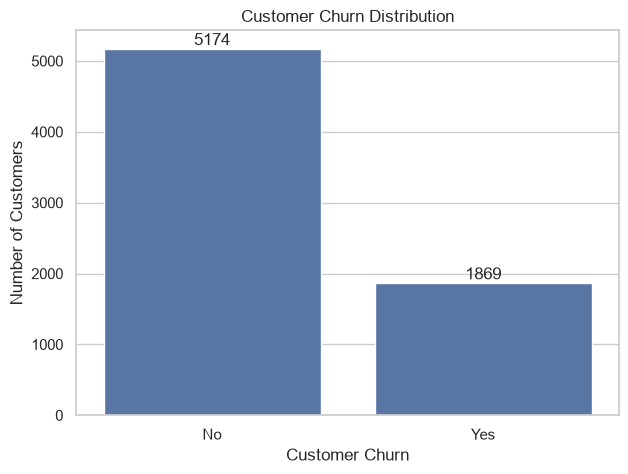

In [14]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [15]:
# Churn distribution by contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


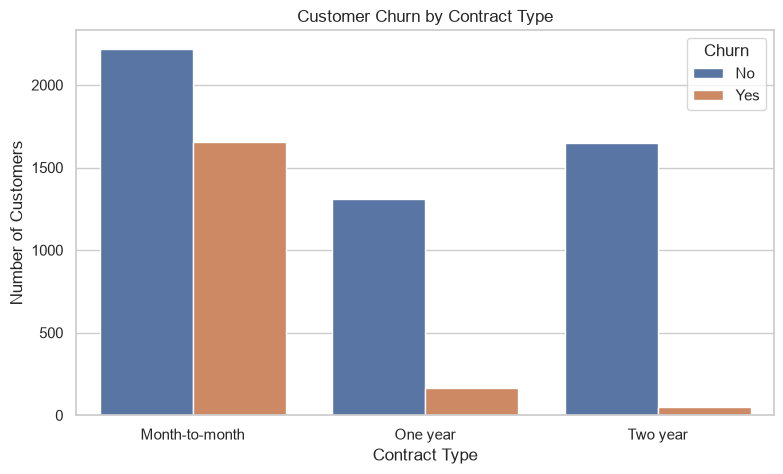

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [17]:
# Create customer tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-60 Months",
        "61-72 Months"
    ]
)

# Calculate churn percentage by tenure group
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

display(tenure_churn.round(2))

Churn,No,Yes
TenureGroup,,
0-12 Months,52.56,47.44
13-24 Months,71.29,28.71
25-48 Months,79.61,20.39
49-60 Months,85.58,14.42
61-72 Months,93.39,6.61


In [18]:
# Churn rate by payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

display(payment_churn.round(2))

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


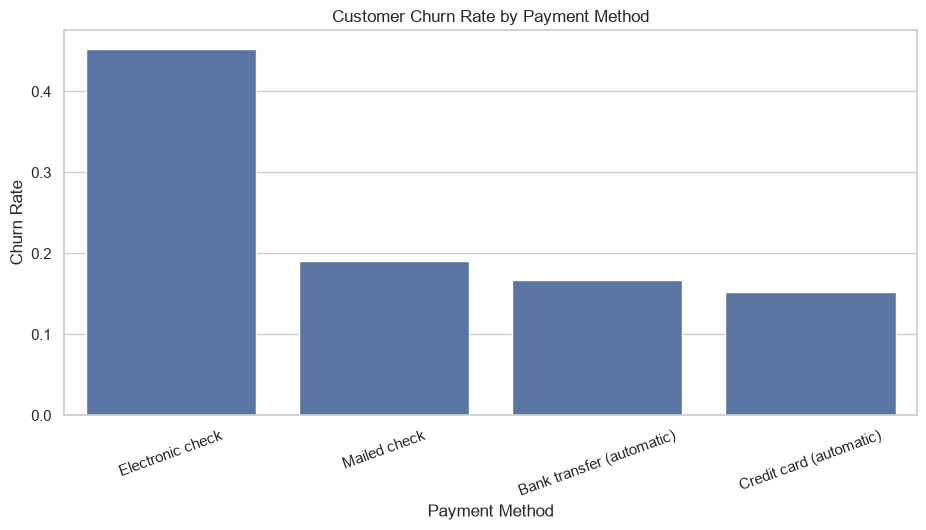

In [19]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=df,
    x="PaymentMethod",
    y=df["Churn"].eq("Yes").astype(int),
    errorbar=None
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate")

plt.xticks(rotation=20)
plt.show()

In [20]:
# Churn rate by Internet Service
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

display(internet_churn.round(2))

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [21]:
# Monthly charges grouped by churn
monthly_charges = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "min", "max"]
)

display(monthly_charges.round(2))

,mean,median,min,max
Churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


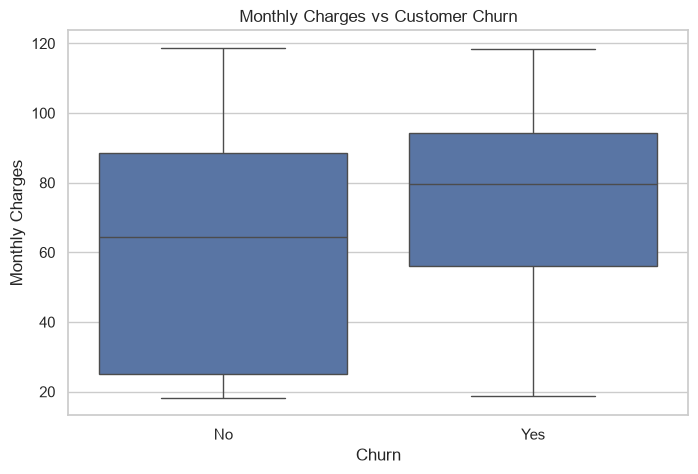

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [23]:
# Churn rate by TechSupport
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

display(support_churn.round(2))

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


In [24]:
# Churn rate by OnlineSecurity
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

display(security_churn.round(2))

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


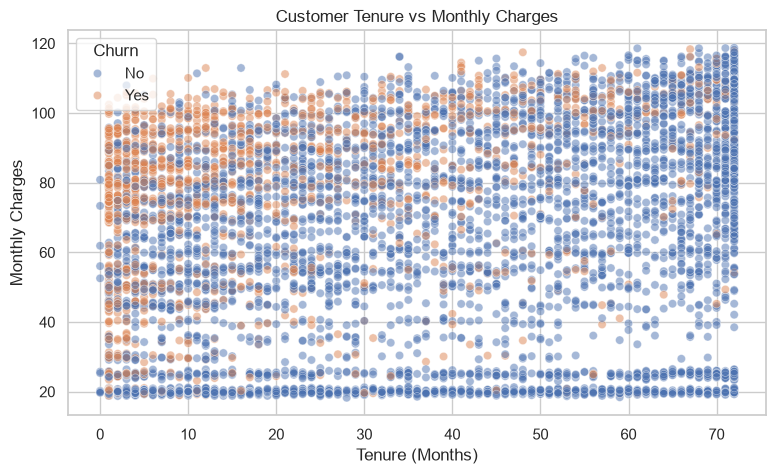

In [25]:
# Relationship between tenure and monthly charges

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    alpha=0.5
)

plt.title("Customer Tenure vs Monthly Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")

plt.show()

In [26]:
correlation = df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()

display(correlation.round(3))


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.248,0.826
MonthlyCharges,0.248,1.000,0.651
TotalCharges,0.826,0.651,1.000


In [27]:
# Encode churn target

df["Churn_Encoded"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Create average monthly revenue indicator
df["AverageMonthlyRevenue"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"]
)

# Customer tenure category
df["CustomerLifecycle"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "New",
        "Developing",
        "Established",
        "Loyal"
    ]
)

# Display engineered features
display(
    df[
        [
            "customerID",
            "tenure",
            "TotalCharges",
            "AverageMonthlyRevenue",
            "CustomerLifecycle",
            "Churn",
            "Churn_Encoded"
        ]
    ].head(10)
)

,customerID,tenure,TotalCharges,AverageMonthlyRevenue,CustomerLifecycle,Churn,Churn_Encoded
0,7590-VHVEG,1,29.85,29.850000,New,No,0
1,5575-GNVDE,34,1889.50,55.573529,Established,No,0
2,3668-QPYBK,2,108.15,54.075000,New,Yes,1
3,7795-CFOCW,45,1840.75,40.905556,Established,No,0
4,9237-HQITU,2,151.65,75.825000,New,Yes,1
5,9305-CDSKC,8,820.50,102.562500,New,Yes,1
6,1452-KIOVK,22,1949.40,88.609091,Developing,No,0
7,6713-OKOMC,10,301.90,30.190000,New,No,0
8,7892-POOKP,28,3046.05,108.787500,Established,Yes,1
9,6388-TABGU,62,3487.95,56.257258,Loyal,No,0


In [28]:
# Churn distribution by customer lifecycle

lifecycle_churn = pd.crosstab(
    df["CustomerLifecycle"],
    df["Churn"],
    normalize="index"
) * 100

display(lifecycle_churn.round(2))

Churn,No,Yes
CustomerLifecycle,,
New,52.56,47.44
Developing,71.29,28.71
Established,79.61,20.39
Loyal,90.49,9.51


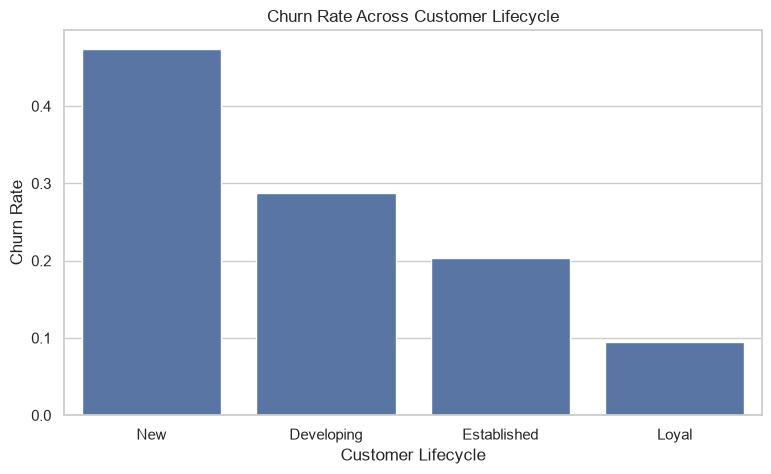

In [29]:
# Visualise churn by customer lifecycle

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="CustomerLifecycle",
    y="Churn_Encoded",
    errorbar=None
)

plt.title("Churn Rate Across Customer Lifecycle")
plt.xlabel("Customer Lifecycle")
plt.ylabel("Churn Rate")

plt.show()

In [30]:
# Create modelling dataset
model_df = df.drop(
    columns=[
        "customerID",
        "Churn",
        "CustomerLifecycle",
        "AverageMonthlyRevenue"
    ]
).copy()

# Separate target variable
X = model_df.drop(columns=["Churn_Encoded"])
y = model_df["Churn_Encoded"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (7043, 20)
Target shape: (7043,)

Target distribution:
Churn_Encoded
0    5174
1    1869
Name: count, dtype: int64


In [31]:
# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumber of categorical features:", len(categorical_columns))

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15


In [32]:
# One-hot encode categorical variables
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

display(X_encoded.head())

Original feature shape: (7043, 20)
Encoded feature shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,TenureGroup,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0-12 Months,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,25-48 Months,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,0-12 Months,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,25-48 Months,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0-12 Months,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [33]:
# Remove redundant tenure grouping
X = X.drop(columns=["TenureGroup"])

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# One-hot encoding
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Final feature matrix:", X_encoded.shape)
print("Remaining categorical columns:",
      X_encoded.select_dtypes(include=["object", "category"]).columns.tolist())

display(X_encoded.head())

Final feature matrix: (7043, 30)
Remaining categorical columns: []


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 30)
Testing features: (1409, 30)

Training target distribution:
Churn_Encoded
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn_Encoded
0    0.735
1    0.265
Name: proportion, dtype: float64


In [35]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

print("LightGBM model trained successfully!")

LightGBM model trained successfully!


Model Evaluation
-----------------------------------
Accuracy:  0.7892
Precision: 0.6156
Recall:    0.5481
F1-Score:  0.5799
ROC-AUC:   0.8300

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



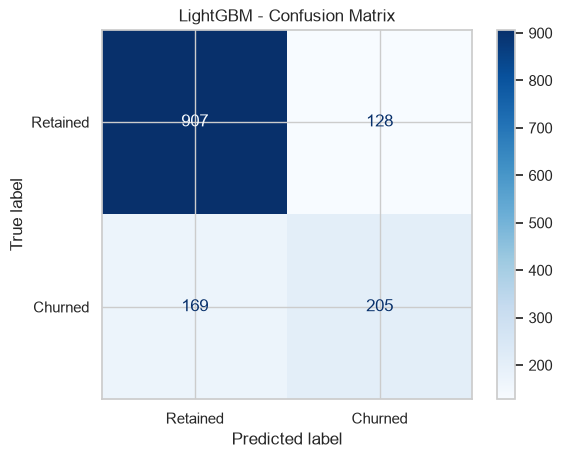

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predictions
y_pred = lgbm_model.predict(X_test)
y_pred_proba = lgbm_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("Model Evaluation")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Retained", "Churned"]
).plot(cmap="Blues")

plt.title("LightGBM - Confusion Matrix")
plt.show()

In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (y_pred_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.30,0.5517,0.7273,0.6275
1,0.35,0.5727,0.6845,0.6236
2,0.40,0.5775,0.6176,0.5969
3,0.45,0.5973,0.5829,0.5900
4,0.50,0.6156,0.5481,0.5799
5,0.55,0.6483,0.5027,0.5663
6,0.60,0.6522,0.4412,0.5263


Classification Report - Threshold 0.30
              precision    recall  f1-score   support

           0       0.89      0.79      0.83      1035
           1       0.55      0.73      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



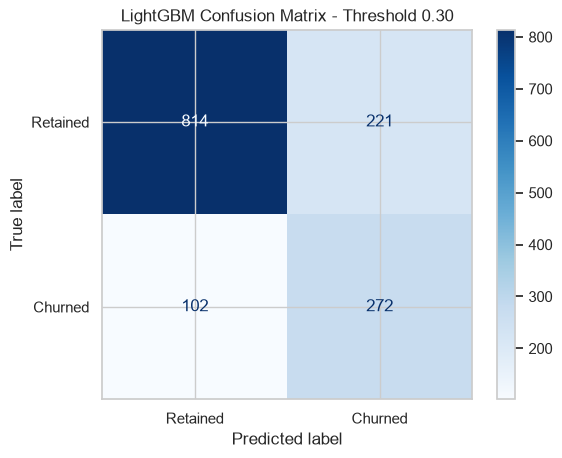

In [38]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

BEST_THRESHOLD = 0.30

y_pred_tuned = (y_pred_proba >= BEST_THRESHOLD).astype(int)

print("Classification Report - Threshold 0.30")
print(classification_report(y_test, y_pred_tuned))

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Retained", "Churned"]
).plot(cmap="Blues")

plt.title("LightGBM Confusion Matrix - Threshold 0.30")
plt.show()